In [1]:
######## snakemake preamble start (automatically inserted, do not edit) ########
import sys;sys.path.extend(['/home/wamesjang/anaconda3/envs/snakemake/lib/python3.13/site-packages', '/home/wamesjang/rockefeller/diagram_dynamic_metabolism_v2/workflow', '/home/wamesjang/anaconda3/envs/snakemake/bin', '/home/wamesjang/anaconda3/envs/snakemake/lib/python3.13', '/home/wamesjang/anaconda3/envs/snakemake/lib/python3.13/lib-dynload', '/home/wamesjang/anaconda3/envs/snakemake/lib/python3.13/site-packages', '/home/wamesjang/.cache/snakemake/snakemake/source-cache/runtime-cache/tmptfpygvzs/file/home/wamesjang/rockefeller/diagram_dynamic_metabolism_v2/workflow/notebooks', '/home/wamesjang/rockefeller/diagram_dynamic_metabolism_v2/workflow/notebooks']);import pickle;from snakemake import script;script.snakemake = pickle.loads(b'\x80\x04\x95\xce\x03\x00\x00\x00\x00\x00\x00\x8c\x10snakemake.script\x94\x8c\tSnakemake\x94\x93\x94)\x81\x94}\x94(\x8c\x05input\x94\x8c\x0csnakemake.io\x94\x8c\nInputFiles\x94\x93\x94)\x81\x94\x8c"resources/data/six_state_trees.pkl\x94a}\x94(\x8c\x06_names\x94}\x94\x8c\x12_allowed_overrides\x94]\x94(\x8c\x05index\x94\x8c\x04sort\x94eh\x10h\x06\x8c\x0eAttributeGuard\x94\x93\x94)\x81\x94}\x94\x8c\x04name\x94h\x10sbh\x11h\x13)\x81\x94}\x94h\x16h\x11sbub\x8c\x06output\x94h\x06\x8c\x0bOutputFiles\x94\x93\x94)\x81\x94\x8c,resources/subfigures/fig_2a_steady_state.svg\x94a}\x94(h\x0c}\x94h\x0e]\x94(h\x10h\x11eh\x10h\x13)\x81\x94}\x94h\x16h\x10sbh\x11h\x13)\x81\x94}\x94h\x16h\x11sbub\x8c\r_params_store\x94h\x06\x8c\x06Params\x94\x93\x94)\x81\x94}\x94(h\x0c}\x94h\x0e]\x94(h\x10h\x11eh\x10h\x13)\x81\x94}\x94h\x16h\x10sbh\x11h\x13)\x81\x94}\x94h\x16h\x11sbub\x8c\r_params_types\x94}\x94\x8c\twildcards\x94h\x06\x8c\tWildcards\x94\x93\x94)\x81\x94}\x94(h\x0c}\x94h\x0e]\x94(h\x10h\x11eh\x10h\x13)\x81\x94}\x94h\x16h\x10sbh\x11h\x13)\x81\x94}\x94h\x16h\x11sbub\x8c\x07threads\x94K\x01\x8c\tresources\x94h\x06\x8c\tResources\x94\x93\x94)\x81\x94(K\x01K\x01\x8c\x04/tmp\x94e}\x94(h\x0c}\x94(\x8c\x06_cores\x94K\x00N\x86\x94\x8c\x06_nodes\x94K\x01N\x86\x94\x8c\x06tmpdir\x94K\x02N\x86\x94uh\x0e]\x94(h\x10h\x11eh\x10h\x13)\x81\x94}\x94h\x16h\x10sbh\x11h\x13)\x81\x94}\x94h\x16h\x11sbhEK\x01hGK\x01hIhBub\x8c\x03log\x94h\x06\x8c\x03Log\x94\x93\x94)\x81\x94\x8c!logs/run_fig2a_steady_state.ipynb\x94a}\x94(h\x0c}\x94\x8c\x08notebook\x94K\x00N\x86\x94sh\x0e]\x94(h\x10h\x11eh\x10h\x13)\x81\x94}\x94h\x16h\x10sbh\x11h\x13)\x81\x94}\x94h\x16h\x11sbhWhTub\x8c\x06config\x94}\x94\x8c\x04rule\x94\x8c\x13fig_2a_steady_state\x94\x8c\x0fbench_iteration\x94N\x8c\tscriptdir\x94\x8cL/home/wamesjang/rockefeller/diagram_dynamic_metabolism_v2/workflow/notebooks\x94ub.');del script;from snakemake.logging import logger;from snakemake.script import snakemake;import os; os.chdir(r'/home/wamesjang/rockefeller/diagram_dynamic_metabolism_v2/workflow');
######## snakemake preamble end #########


In [2]:
# start coding here
import mpmath
import numpy as np
import bokeh.layouts
import bokeh.models
import bokeh.plotting

from IPython.display import display
from jupyter_bokeh.widgets import BokehModel
from bokeh.io import output_notebook, export_svg, export_png
from bokeh.plotting import figure
from ipywidgets import interact

from bokeh.io import output_file, show, export_svgs
from bokeh.layouts import row
from bokeh.models import Ellipse, GraphRenderer, StaticLayoutProvider, Circle
from bokeh.palettes import Spectral6, Reds3, brewer
from bokeh.plotting import figure
from IPython.display import display
from bokeh.models import (Arrow, Label, NormalHead, OpenHead,
                          Plot, Range1d, TeeHead, VeeHead)
from bokeh.models import MathML
from lib.six_state_model import dynamic_steady_state_diagram
import pickle as pkl
output_notebook()
with open(snakemake.input[0], 'rb') as f:
    spanTreesGraph = pkl.load(f)

Loading BokehJS ...

In [3]:
oscMidpoint = 0
k_bT = 1
dG_1 = 2
dG_2 = 2
epsilon = 0

alpha_21 = 1
alpha_32 = 1

alpha_54 = 1 
alpha_65 = 1 
gamma = 2E5
N = 6
node_indices = list(range(N))

# s1 = figure(title="Flux Diagram", x_range=(-1.1,1.1), y_range=(0.2,1.8), tools="hover", tooltips="index: @name", toolbar_location=None, width=208, height=208)
# s1.axis.visible = False

# graph = GraphRenderer()

# graph.node_renderer.data_source.add(np.array(node_indices), 'index')
# graph.node_renderer.data_source.add(np.array(node_indices) + 1, 'name')
# graph.node_renderer.data_source.add(Spectral6, 'color')
# graph.node_renderer.glyph = Circle(radius=0.1, fill_color="color")

# # s = [0, 2, 1, 1, 2, 3, 1, 2, 3, 3, 0, 0, 3, 2, 3, 4, 3, 5, 5, 5]
# # e = [1, 0, 2, 3, 3, 0, 0, 1, 1, 2, 3, 4, 4, 5, 5, 0, 4, 2, 3, 4]
# # s = [0, 2, 1, 1, 1, 2, 3, 0, 3, 2, 3, 4, 3, 5, 5, 5]
# # e = [1, 0, 2, 3, 0, 1, 1, 4, 4, 5, 5, 0, 4, 2, 3, 4]

# s = [0, 0, 1, 1, 2, 3, 4, 1, 3, 2, 4, 5, 4, 5, 2, 5]
# e = [1, 3, 2, 4, 5, 4, 5, 0, 0, 1, 1, 2, 3, 4, 0, 3]

# graph.edge_renderer.data_source.data = dict(
#     start=s,
#     end=e)

# ### start of layout code
# x = [-0.5, 0, 0.5, -0.5, 0, 0.5]
# y = np.array([0.5, 0.5, 0.5, -0.5, -0.5, -0.5]) + 0.5
# graph_layout = dict(zip(range(len(node_indices)), zip(x, y)))
# graph.layout_provider = StaticLayoutProvider(graph_layout=graph_layout)


# ### Draw quadratic bezier paths
# def bezier(start, end, control, steps):
#     return [(1-s)**2*start + 2*(1-s)*s*control + s**2*end for s in steps]
# vSize=6
# xs, ys = [], []
# steps = [i/100. for i in range(100)]
# for edge_index in range(len(s)):
#     sx, sy = graph_layout[s[edge_index]]
#     ex, ey = graph_layout[e[edge_index]]
#     match edge_index:
#         # s = [0, 0, 1, 1, 2, 3, 4, 1, 3, 2, 4, 5, 4, 5, 2, 5]
#         # e = [1, 3, 2, 4, 5, 4, 5, 0, 0, 1, 1, 2, 3, 4, 0, 3]
#         case 0:
#             x = bezier(sx, ex, -0.25, steps)
#             y = bezier(sy, ey, 1.25, steps)
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-8], y_start=y[-8], x_end=x[-7], y_end=y[-7], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)
    
#         case 1: 
#             x = bezier(sx, ex, -0.75, steps)
#             y = bezier(sy, ey, 0.5, steps)    
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-5], y_start=y[-5], x_end=x[-4], y_end=y[-4], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)
#         case 2:
#             x = bezier(sx, ex, 0.25, steps)
#             y = bezier(sy, ey, 1.25, steps)   
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-7], y_start=y[-7], x_end=x[-6], y_end=y[-6], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)
#         case 3:
#             x = bezier(sx, ex, -0.25, steps)
#             y = bezier(sy, ey, 0.5, steps)    
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-5], y_start=y[-5], x_end=x[-4], y_end=y[-4], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)
#         case 4:
#             x = bezier(sx, ex, 0.25, steps)
#             y = bezier(sy, ey, 0.5, steps)    
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-7], y_start=y[-7], x_end=x[-6], y_end=y[-6], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)
#         case 5:
#             x = bezier(sx, ex, -0.25, steps)
#             y = bezier(sy, ey, 0.25, steps)
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-8], y_start=y[-8], x_end=x[-7], y_end=y[-7], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)
#         case 6:
#             x = bezier(sx, ex, 0.25, steps)
#             y = bezier(sy, ey, 0.25, steps)
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-8], y_start=y[-8], x_end=x[-7], y_end=y[-7], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)
#         case 7:
#             x = bezier(sx, ex, -0.25, steps)
#             y = bezier(sy, ey, 0.75, steps)
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-8], y_start=y[-8], x_end=x[-7], y_end=y[-7], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)
#         case 8:
#             x = bezier(sx, ex, -0.25, steps)
#             y = bezier(sy, ey, 0.5, steps)    
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-7], y_start=y[-7], x_end=x[-6], y_end=y[-6], end=VeeHead(size=vSize))
#             # s1.add_layout(arrow)
#         case 9: 
#             x = bezier(sx, ex, 0.25, steps)
#             y = bezier(sy, ey, 0.75, steps)    
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-5], y_start=y[-5], x_end=x[-4], y_end=y[-4], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)
#         case 10:
#             x = bezier(sx, ex, 0.25, steps)
#             y = bezier(sy, ey, 0.5, steps)   
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-7], y_start=y[-7], x_end=x[-6], y_end=y[-6], end=VeeHead(size=vSize))
#             # s1.add_layout(arrow)
#         case 11:
#             x = bezier(sx, ex, 0.75, steps)
#             y = bezier(sy, ey, 0.5, steps)    
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-5], y_start=y[-5], x_end=x[-4], y_end=y[-4], end=VeeHead(size=vSize))
#             # s1.add_layout(arrow)
#         case 12:
#             x = bezier(sx, ex, -0.25, steps)
#             y = bezier(sy, ey, -0.25, steps)    
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-7], y_start=y[-7], x_end=x[-6], y_end=y[-6], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)
#         case 13:
#             x = bezier(sx, ex, 0.25, steps)
#             y = bezier(sy, ey, -0.25, steps)
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-8], y_start=y[-8], x_end=x[-7], y_end=y[-7], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)
#         case 14:
#             x = bezier(sx, ex, 0, steps)
#             y = bezier(sy, ey, 2.0, steps)
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-4], y_start=y[-4], x_end=x[-3], y_end=y[-3], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)
#         case 15:
#             x = bezier(sx, ex, 0, steps)
#             y = bezier(sy, ey, -1.0, steps)
#             xs.append(x)
#             ys.append(y)
#             arrow = Arrow(x_start=x[-4], y_start=y[-4], x_end=x[-3], y_end=y[-3], end=VeeHead(size=vSize))
#             s1.add_layout(arrow)

#         case _:
#             xs.append(np.linspace(sx, ex, 100))
#             ys.append(np.linspace(sy, ey, 100))
    

  
    
# graph.edge_renderer.data_source.data['xs'] = xs
# graph.edge_renderer.data_source.data['ys'] = ys



# s1.renderers.append(graph)

# probabilities = [r'$$p_1$$', r'$$p_2$$', r'$$p_3$$']
# # probabilities = [r'$$p_1$$', r'$$p_2$$', r'$$p_3$$', r'$$p_4$$', r'$$p_5$$', r'$$p_6$$']
# fluxes = [r'Path 1', r'Path 2', r'Path 1 + Path 2']

# s2 = figure(title="State probabilities", x_range=probabilities, y_range=(0,1.0), tools="", toolbar_location=None, width=208, height=208)
# source_1 = bokeh.models.ColumnDataSource(data=dict(x=probabilities, top=[0,0,0], color=Spectral6[:3]))
# # source_1 = bokeh.models.ColumnDataSource(data=dict(x=probabilities, top=[0,0,0, 0, 0,0], color=Spectral6))

# s2.vbar(x='x', top='top', width=0.9, source=source_1, color='color')

s3 = figure(title="Flux", x_range=(-5, 5), y_range=(0,5), tools="", toolbar_location=None, width=170, height=170)

epsilon_list = np.linspace(-5,5,50)
J_tot_list = []
J_limit_1_list = []
J_limit_2_list = []

for epsilon in epsilon_list:
    epsilon_1 = epsilon
    epsilon_2 = epsilon
    alpha_14 = 1e-11
    alpha_41 = 1e-11
    # alpha_41 = alpha_14
    J_1, J_2, J_3, J_4, J_5, J_6, J_7, J_8, J_9, J_10, J_11, J_f1, J_f2, J_f3 = dynamic_steady_state_diagram(epsilon_1, epsilon_2, alpha_21, alpha_32, gamma, gamma, alpha_14, alpha_41, dG_1=dG_1, dG_2=dG_2, k_bT=1, spanTreesGraph=spanTreesGraph)
    J_1 = float(J_1)
    J_2 = float(J_2)
    J_3 = float(J_3)
    J_4 = float(J_4)
    J_5 = float(J_5)
    J_6 = float(J_6)
    J_7 = float(J_7)
    J_8 = float(J_8)
    J_9 = float(J_9)
    J_10 = float(J_10)
    J_11 = float(J_11)
    J_f1 = float(J_f1)
    J_f2 = float(J_f2)
    J_f3 = float(J_f3)
    
    J_tot = np.abs(J_4) + np.abs(J_5) + np.abs(J_6) + np.abs(J_7) + np.abs(J_8) + np.abs(J_9) + np.abs(J_10) + np.abs(J_11)
    J_tot_list.append(J_tot)

    J_1, J_2, J_3, J_4, J_5, J_6, J_7, J_8, J_9, J_10, J_11, J_f1, J_f2, J_f3 = dynamic_steady_state_diagram(epsilon_1, epsilon_2, alpha_21, alpha_32, gamma, gamma, alpha_14, alpha_41, dG_1=100, dG_2=dG_2, k_bT=1, spanTreesGraph=spanTreesGraph)
    J_1 = float(J_1)
    J_2 = float(J_2)
    J_3 = float(J_3)
    J_4 = float(J_4)
    J_5 = float(J_5)
    J_6 = float(J_6)
    J_7 = float(J_7)
    J_8 = float(J_8)
    J_9 = float(J_9)
    J_10 = float(J_10)
    J_11 = float(J_11)
    J_f1 = float(J_f1)
    J_f2 = float(J_f2)
    J_f3 = float(J_f3)
    J_tot = np.abs(J_4) + np.abs(J_5) + np.abs(J_6) + np.abs(J_7) + np.abs(J_8) + np.abs(J_9) + np.abs(J_10) + np.abs(J_11)
    J_limit_1_list.append(J_tot)

    J_1, J_2, J_3, J_4, J_5, J_6, J_7, J_8, J_9, J_10, J_11, J_f1, J_f2, J_f3 = dynamic_steady_state_diagram(epsilon_1, epsilon_2, alpha_21, alpha_32, gamma, gamma, alpha_14, alpha_41, dG_1=dG_1, dG_2=100, k_bT=1, spanTreesGraph=spanTreesGraph)
    J_1 = float(J_1)
    J_2 = float(J_2)
    J_3 = float(J_3)
    J_4 = float(J_4)
    J_5 = float(J_5)
    J_6 = float(J_6)
    J_7 = float(J_7)
    J_8 = float(J_8)
    J_9 = float(J_9)
    J_10 = float(J_10)
    J_11 = float(J_11)
    J_f1 = float(J_f1)
    J_f2 = float(J_f2)
    J_f3 = float(J_f3)
    J_tot = np.abs(J_4) + np.abs(J_5) + np.abs(J_6) + np.abs(J_7) + np.abs(J_8) + np.abs(J_9) + np.abs(J_10) + np.abs(J_11)
    J_limit_2_list.append(J_tot)


source_2 = bokeh.models.ColumnDataSource(data=dict(x=epsilon_list, y=J_tot_list))
source_3 = bokeh.models.ColumnDataSource(data=dict(x=epsilon_list, y=J_limit_1_list))
source_4 = bokeh.models.ColumnDataSource(data=dict(x=epsilon_list, y=J_limit_2_list))
idx = np.argmin(np.abs(epsilon_list - epsilon))


intersect = s3.circle([epsilon_list[idx]], [J_tot_list[idx]], size=8, color='red')
s3.line(x='x', y='y', source=source_2, line_width=2, color='black')
s3.line(x='x', y='y', source=source_3, line_width=2, color='#92278f', line_dash='dashdot')
s3.line(x='x', y='y', source=source_4, line_width=2, color='#f7941d', line_dash='dashdot')
s3.xaxis.axis_label_text_font_size = "11pt"
s3.yaxis.axis_label_text_font_size = "11pt"
s3.xaxis.axis_label = '$$\\epsilon \ (k_B T)$$'
s3.xaxis.axis_label = '$$\Delta G_{bind} \ (k_B T)$$'
s3.yaxis.axis_label = '$$J_{tot}$$ [$$1/s$$]'
 
def update(epsilon=0, gamma=10, dG_1=2, dG_2=2, alpha_21=1, alpha_32=1):
    idx = np.argmin(np.abs(epsilon_list - epsilon))
    alpha_54 = alpha_21
    alpha_65 = alpha_32
    epsilon_1 = epsilon
    epsilon_2 = epsilon
    alpha_14 = 1e11
    alpha_41 = 1e11 
    # alpha_41 = alpha_14
    # p1, p2, p3, p4, p5, p6 = solve_p_dynamic_steady_state(epsilon_1, epsilon_2, alpha_21, alpha_32, gamma, gamma, alpha_14, alpha_41, dG_1=dG_1, dG_2=dG_2, k_bT=1)
    # p1 = float(p1)
    # p2 = float(p2)
    # p3 = float(p3)
    # p4 = float(p4)
    # p5 = float(p5)
    # p6 = float(p6)
    
    # alpha_12 = alpha_21 * np.exp((dG_1 + epsilon_1) / k_bT)
    # alpha_23 = alpha_32 * np.exp((dG_2 - epsilon_1)/ k_bT)


    # alpha_45 = alpha_54 * np.exp((dG_1 + epsilon_2) / k_bT)
    # alpha_56 = alpha_65 * np.exp((dG_2 - epsilon_2) / k_bT)

    # alpha_25 = alpha_14
    # alpha_52 = alpha_41
    # alpha_36 = alpha_14
    # alpha_63 = alpha_41
   
    # source_1.data = dict(x=probabilities, top=[p1 + p4, p2 + p5, p3 + p6], color=Spectral6[:3])
    # # source_1.data = dict(x=probabilities, top=[p1, p2, p3,  p4, p5, p6], color=Spectral6)

    # # s = [0, 0, 1, 1, 2, 3, 4, 1, 3, 2, 4, 5, 4, 5, 2, 5]
    # # e = [1, 3, 2, 4, 5, 4, 5, 0, 0, 1, 1, 2, 3, 4, 0, 3]
    # J_12 = np.max([p1 * alpha_12, 0.01])
    # J_21 = np.max([p2 * alpha_21, 0.01])

    # J_23 = np.max([p2 * alpha_23, 0.01])
    # J_32 = np.max([p3 * alpha_32, 0.01])

    # J_45 = np.max([p4 * alpha_45, 0.01])
    # J_54 = np.max([p5 * alpha_54, 0.01])

    # J_56 = np.max([p5 * alpha_56, 0.01])
    # J_65 = np.max([p6 * alpha_65, 0.01])

    # J_41 = np.max([p4 * alpha_41, 0.01])
    # J_14 = np.max([p1 * alpha_14, 0.01])

    # J_52 = np.max([p5 * alpha_52, 0.01])
    # J_25 = np.max([p2 * alpha_25, 0.01])

    # J_36 = np.max([p3 * alpha_36, 0.01])
    # J_63 = np.max([p6 * alpha_63, 0.01])

    # J_31 = np.max([p3 * gamma, 0.01])
    # J_64 = np.max([p6 * gamma, 0.01])

    # blank = 1e-11
    # graph.edge_renderer.data_source.data["line_width"] = np.array([J_12, blank, J_23, blank, blank, J_45, J_56, J_21, blank, J_32, blank, blank, J_54, J_65, J_31, J_64])
    # # graph.edge_renderer.data_source.data["line_width"] = [1] * len(s)
    # graph.edge_renderer.glyph.line_width = {'field': 'line_width'}


    J_tot_list = []
    J_limit_1_list = []
    J_limit_2_list = []
    for epsilon in epsilon_list:
        epsilon_1 = epsilon
        epsilon_2 = epsilon
        J_1, J_2, J_3, J_4, J_5, J_6, J_7, J_8, J_9, J_10, J_11, J_f1, J_f2, J_f3 = dynamic_steady_state_diagram(epsilon_1, epsilon_2, alpha_21, alpha_32, gamma, gamma, alpha_14, alpha_41, dG_1=dG_1, dG_2=dG_2, k_bT=1, spanTreesGraph=spanTreesGraph)
        J_1 = float(J_1)
        J_2 = float(J_2)
        J_3 = float(J_3)
        J_4 = float(J_4)
        J_5 = float(J_5)
        J_6 = float(J_6)
        J_7 = float(J_7)
        J_8 = float(J_8)
        J_9 = float(J_9)
        J_10 = float(J_10)
        J_11 = float(J_11)
        J_f1 = float(J_f1)
        J_f2 = float(J_f2)
        J_f3 = float(J_f3)
        J_tot = np.abs(J_4) + np.abs(J_5) + np.abs(J_6) + np.abs(J_7) + np.abs(J_8) + np.abs(J_9) + np.abs(J_10) + np.abs(J_11)
        J_tot_list.append(J_tot)

        J_1, J_2, J_3, J_4, J_5, J_6, J_7, J_8, J_9, J_10, J_11, J_f1, J_f2, J_f3 = dynamic_steady_state_diagram(epsilon_1, epsilon_2, alpha_21, alpha_32, gamma, gamma, alpha_14, alpha_41, dG_1=100, dG_2=dG_2, k_bT=1, spanTreesGraph=spanTreesGraph)
        J_1 = float(J_1)
        J_2 = float(J_2)
        J_3 = float(J_3)
        J_4 = float(J_4)
        J_5 = float(J_5)
        J_6 = float(J_6)
        J_7 = float(J_7)
        J_8 = float(J_8)
        J_9 = float(J_9)
        J_10 = float(J_10)
        J_11 = float(J_11)
        J_f1 = float(J_f1)
        J_f2 = float(J_f2)
        J_f3 = float(J_f3)
        J_tot = np.abs(J_4) + np.abs(J_5) + np.abs(J_6) + np.abs(J_7) + np.abs(J_8) + np.abs(J_9) + np.abs(J_10) + np.abs(J_11)
        J_limit_1_list.append(J_tot)

        J_1, J_2, J_3, J_4, J_5, J_6, J_7, J_8, J_9, J_10, J_11, J_f1, J_f2, J_f3 = dynamic_steady_state_diagram(epsilon_1, epsilon_2, alpha_21, alpha_32, gamma, gamma, alpha_14, alpha_41, dG_1=dG_1, dG_2=100, k_bT=1, spanTreesGraph=spanTreesGraph)
        J_1 = float(J_1)
        J_2 = float(J_2)
        J_3 = float(J_3)
        J_4 = float(J_4)
        J_5 = float(J_5)
        J_6 = float(J_6)
        J_7 = float(J_7)
        J_8 = float(J_8)
        J_9 = float(J_9)
        J_10 = float(J_10)
        J_11 = float(J_11)
        J_f1 = float(J_f1)
        J_f2 = float(J_f2)
        J_f3 = float(J_f3)
        J_tot = np.abs(J_4) + np.abs(J_5) + np.abs(J_6) + np.abs(J_7) + np.abs(J_8) + np.abs(J_9) + np.abs(J_10) + np.abs(J_11)
        J_limit_2_list.append(J_tot)



    source_2.data = dict(x=epsilon_list, y=J_tot_list)
    source_3.data = dict(x=epsilon_list, y=J_limit_1_list)
    source_4.data = dict(x=epsilon_list, y=J_limit_2_list)
    
    intersect.data_source.data['y'] = [J_tot_list[idx]]
    intersect.data_source.data['x'] = [epsilon_list[idx]]
    
    
# plotting new graph

# plot = row(s1, s3, s2)
plot = row(s3)
interact(update, epsilon=(-5,5, 0.1), gamma=(0, 20, 0.1,), dG_1 = (-5,5,0.1), dG_2 = (-5,5,0.1), alpha_21 = (0.1,100,0.1), alpha_32 = (0.1,100,0.1))
# s1.output_backend = "svg"
# s2.output_backend = "svg"
s3.output_backend = "svg"
# export_svg(plot, filename=snakemake.output[0])

display(BokehModel(plot))
output_notebook()


<>:276: SyntaxWarning: invalid escape sequence '\ '
<>:277: SyntaxWarning: invalid escape sequence '\D'
<>:276: SyntaxWarning: invalid escape sequence '\ '
<>:277: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_491139/982713252.py:276: SyntaxWarning: invalid escape sequence '\ '
  s3.xaxis.axis_label = '$$\\epsilon \ (k_B T)$$'
/tmp/ipykernel_491139/982713252.py:277: SyntaxWarning: invalid escape sequence '\D'
  s3.xaxis.axis_label = '$$\Delta G_{bind} \ (k_B T)$$'


interactive(children=(FloatSlider(value=0.0, description='epsilon', max=5.0, min=-5.0), FloatSlider(value=10.0…

BokehModel(render_bundle={'docs_json': {'2c4715b5-1a5d-4242-9d25-900cbae7af86': {'version': '3.6.2', 'title': …

Loading BokehJS ...

<>:10: SyntaxWarning: invalid escape sequence '\e'
<>:11: SyntaxWarning: invalid escape sequence '\ '
<>:10: SyntaxWarning: invalid escape sequence '\e'
<>:11: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_491139/2316166226.py:10: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
/tmp/ipykernel_491139/2316166226.py:11: SyntaxWarning: invalid escape sequence '\ '
  plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


... (80 outputs left out)

findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.


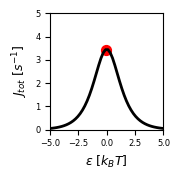

In [4]:
import matplotlib.pyplot as plt
plt.figure(figsize=(1.9,1.9))
# s3 = figure(title="Flux", x_range=(-5, 5), y_range=(0,5), tools="", toolbar_location=None, width=170, height=170)
plt.rcParams['font.sans-serif'] = ['Lucida Sans']
plt.xlim(-5, 5)
plt.ylim(0, 5)
plt.plot(epsilon_list, J_tot_list, color='black', label='Total Flux', linewidth=2)
# plt.plot(epsilon_list, J_limit_1_list, color='#92278f', linestyle='dashdot', label='Limit 1', linewidth=2)
# plt.plot(epsilon_list, J_limit_2_list, color='#f7941d', linestyle='dashdot', label='Limit 2', linewidth=2)
plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.xticks([-5, -2.5, 0, 2.5, 5], fontsize=6)
plt.yticks([i for i in range(0, 6)], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
idx = np.argmin(np.abs(epsilon_list - epsilon_list[np.where(np.array(J_tot_list) == np.max(J_tot_list))[0][0]]))
plt.scatter(epsilon_list[idx], J_tot_list[idx], color='red', s=50, label='Current Point')
# plt.legend()
plt.tight_layout()
plt.savefig(snakemake.output[0], format='svg')